In [178]:
import sys
from pathlib import Path
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from scipy import signal
from scipy.signal import savgol_filter
from scipy.signal.windows import hann

def time_axis(fs, duration):
    T = 1/fs
    t = np.arange(0, duration, T)
    return t

def generate_sine(f, t, A=1, p=0):
    y = A * np.sin(2 * np.pi * f * t + p)
    return y

def spectrum(x, NFFT=-1):
    if NFFT == -1:
        NFFT = len(x)
    X = np.fft.fft(x, NFFT)
    N = len(X)
    X = X[:N//2]
    mag = np.abs(X)*2/N
    freq = np.arange( len(mag) ) * fs / N
    return freq, mag

matplotlib.rcParams["font.family"] = ["Tahoma", "Leelawadee UI", "DejaVu Sans"]
matplotlib.rcParams["axes.unicode_minus"] = False

PROJECT_ROOT = Path(r"C:\Users\khaok\69-1\DSP\FinalProject")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.common.constants import SOURCE_CLIPS_S1_DIR
from src.io.audio_io import load_wav_mono, align_signal_lengths, inspect_dataset
from src.simulation.room_simulator import (
    create_fixed_room_ir,
    simulate_static_room_echo,
    apply_position_movement,
    create_moving_room_irs,
    simulate_moving_room_echo,
    get_scenario_audio,
)


In [179]:
print("=== ทดสอบที่ 1: ดูภาพรวมทุกแบบ ===")
summary = inspect_dataset()

print("\n=== ทดสอบที่ 2.1: เจาะดูเฉพาะแบบที่ 1 (1 คน ไม่เคลื่อนที่) ===")
pairs = inspect_dataset(target=1)
# print("\n=== ทดสอบที่ 2.2: เจาะดูเฉพาะแบบที่ 2 (2 คน ไม่เคลื่อนที่) ===")
# pairs = inspect_dataset(target=2)
# print("\n=== ทดสอบที่ 2.3: เจาะดูเฉพาะแบบที่ 3 (1 คน เคลื่อนที่) ===")
# pairs = inspect_dataset(target=3)
# print("\n=== ทดสอบที่ 2.4: เจาะดูเฉพาะแบบที่ 4 (2 คน คลื่อนที่) ===")
# pairs = inspect_dataset(target=4)

# -------------------------------------------------------------
# แบบที่ 1: ไม่ระบุห้องสะท้อนเสียง (reverb_level=None) -> ได้เฉพาะ (t, raw, fs)
# -------------------------------------------------------------
print("\n=== แบบที่ 1: ดึงเฉพาะสัญญาณดิบ (3 ค่า) ===\n")
t, raw, fs = get_scenario_audio(scenario=1, clip_idx1=0)
print(f"- ความยาวสัญญาณ: {len(raw)} จุด ({len(raw)/fs:.1f} วินาที)")
print(f"- Sampling rate: {fs} Hz")

# -------------------------------------------------------------
# แบบที่ 2: ระบุระดับห้องสะท้อนเสียง low(0), mid(1), high(2) -> ได้ (t, raw, echo, fs)
# -------------------------------------------------------------
print("\n=== แบบที่ 2: ระบุห้องสะท้อนเสียง mid(1) -> ได้ 4 ค่าพร้อม echo ===")
t, raw, echo, fs = get_scenario_audio(scenario=1, clip_idx1=0, reverb_level=1)
print(f"- ความยาว raw: {len(raw)} จุด, echo: {len(echo)} จุด")

=== ทดสอบที่ 1: ดูภาพรวมทุกแบบ ===
สรุปภาพรวมชุดข้อมูลเสียงคนพูดจริง (ทั้งหมด 4 รูปแบบ):
- 1) 1_person_static (1 คน ไม่เคลื่อนที่)    : มี 10 ตัวอย่าง
- 2) 1_person_moving (1 คน เคลื่อนที่)       : มี 10 ตัวอย่าง
- 3) 2_persons_static (2 คน ไม่เคลื่อนที่)   : มี 09 ตัวอย่าง
- 4) 2_persons_moving (2 คน เคลื่อนที่)      : มี 09 ตัวอย่าง
💡 Tip: ใส่ target=1 ถึง 4 เพื่อเจาะจงดูรายละเอียดของแต่ละแบบได้

=== ทดสอบที่ 2.1: เจาะดูเฉพาะแบบที่ 1 (1 คน ไม่เคลื่อนที่) ===
--- [แบบที่ 1: 1 คน ไม่เคลื่อนที่] มีทั้งหมด 10 ตัวอย่าง ---
[00] clip_01_1EbxxdNtTU6sfStbSi-xbA_doubletalk.wav
[01] clip_02_6qaoi9k6Qk2RWUgx68erSQ_doubletalk.wav
[02] clip_03_AbbfwwrUbU2rrCgs69mg6A_doubletalk.wav
[03] clip_04_B6yQraHQwUmDdgts6zSckg_doubletalk.wav
[04] clip_05_CchZxh-H7kGCeACO8l_MZg_doubletalk.wav
[05] clip_06_GP5G30waQ0qEii-l8avBdw_doubletalk.wav
[06] clip_07_KG7t-N2Q9EG_lY_eJaJWlA_doubletalk.wav
[07] clip_08_KTSv-QqiXE6AtMHghJN4Pg_doubletalk.wav
[08] clip_09_MlZqzzdyBE6pvFaHBmi_5g_doubletalk.wav
[09] clip_10_NX

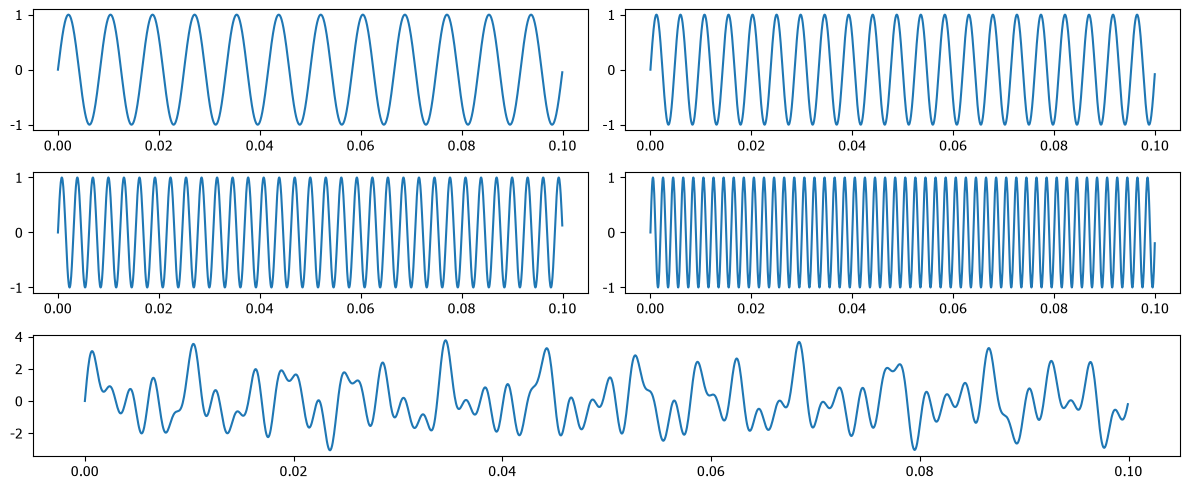

In [180]:
fs = 16000           
duration = 0.1
t = time_axis(fs, duration)
x1 = generate_sine(120,t)
x2 = generate_sine(210,t)
x3 = generate_sine(325, t)
x4 = generate_sine(500,t)
x = x1+x2+x3+x4
plt.figure(figsize=(12,5))
plt.subplot(3,2,1)
plt.plot(t,x1)
plt.subplot(3,2,2)
plt.plot(t,x2)
plt.subplot(3,2,3)
plt.plot(t,x3)
plt.subplot(3,2,4)
plt.plot(t,x4)
plt.subplot(3,1,3)
plt.plot(t,x)
plt.tight_layout()

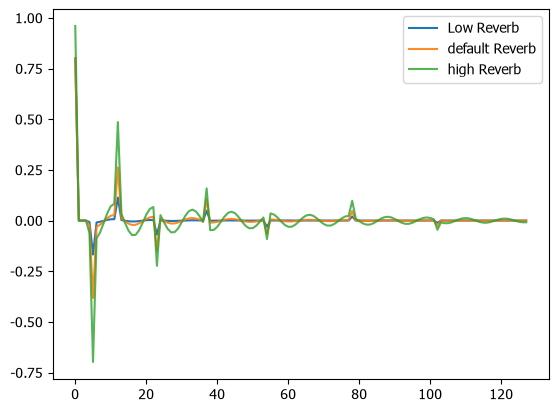

In [181]:
h_low = create_fixed_room_ir(reverb_level="low")
h_default = create_fixed_room_ir()
h_high = create_fixed_room_ir(reverb_level="high", echo_gain=1.2)

plt.plot(h_low, label="Low Reverb")
plt.plot(h_default, label="default Reverb", alpha=0.9)
plt.plot(h_high, label="high Reverb", alpha=0.8)

plt.legend()

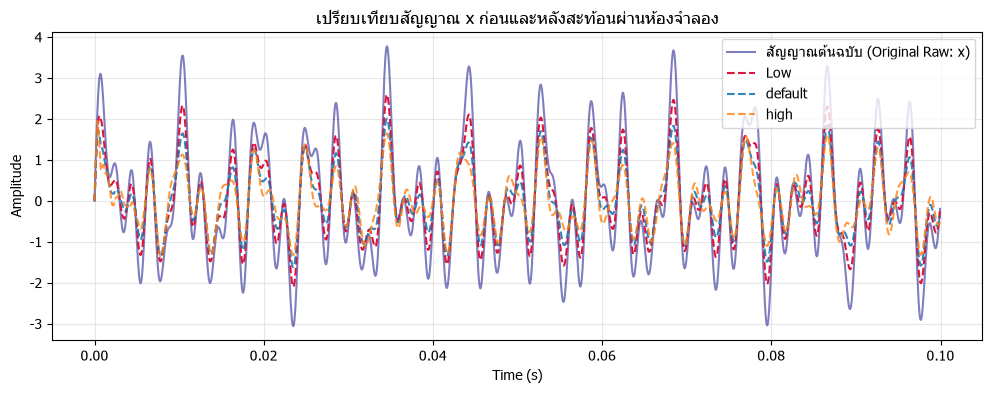

In [182]:
_, x_echo_low, _, _ = simulate_static_room_echo(x, h_low, length_mode="trim")
_, x_echo_default, _, _ = simulate_static_room_echo(x, h_default, length_mode="trim")
_, x_echo_high, _, _ = simulate_static_room_echo(x, h_high, length_mode="trim")


plt.figure(figsize=(12, 4))
plt.plot(t, x, label="สัญญาณต้นฉบับ (Original Raw: x)", color="navy", alpha=0.5)
plt.plot(t, x_echo_low, label="Low", color="crimson", linestyle="--", )
plt.plot(t, x_echo_default, label="default", linestyle="--", alpha=0.9)
plt.plot(t, x_echo_high, label="high", linestyle="--", alpha=0.8)
plt.title("เปรียบเทียบสัญญาณ x ก่อนและหลังสะท้อนผ่านห้องจำลอง")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.legend(loc="upper right")
plt.grid(True, alpha=0.3)
plt.show()

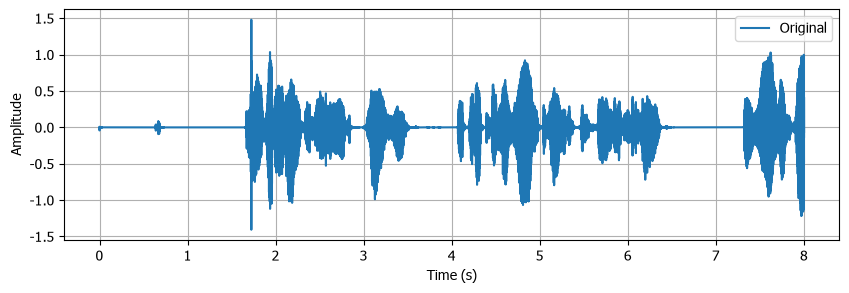

[Echo Lag] โหมด: สุ่มอัตโนมัติ (Random 3-20 ms) -> ใช้ Lag = 15.28 ms (244 samples)


<Figure size 640x480 with 0 Axes>

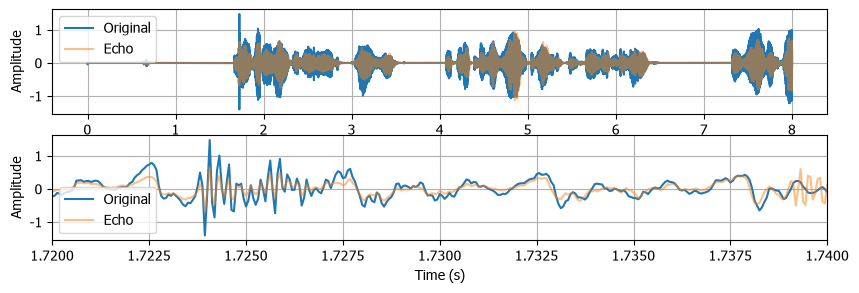

<Figure size 640x480 with 0 Axes>

In [183]:
t, raw, fs = get_scenario_audio(scenario=3, clip_idx1=1)
plt.figure(figsize=(10, 3))
plt.plot(t,raw, label ="Original")
plt.legend()
plt.grid(True)
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.show()
plt.tight_layout()

t, raw, echo, fs = get_scenario_audio(scenario=3, clip_idx1=1, reverb_level=1)
plt.figure(figsize=(10, 3))
plt.subplot(2,1,1)
plt.plot(t,raw, label ="Original")
plt.plot(t,echo, label ="Echo", alpha = 0.5)
plt.legend()
plt.grid(True)
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.subplot(2,1,2)
plt.plot(t,raw, label ="Original")
plt.plot(t,echo, label ="Echo", alpha = 0.5)
plt.xlim(1.72, 1.74)
plt.legend()
plt.grid(True)
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.show()
plt.tight_layout()

[Echo Lag] โหมด: กำหนดค่าเอง (Custom) -> ใช้ Lag = 0.00 ms (0 samples)


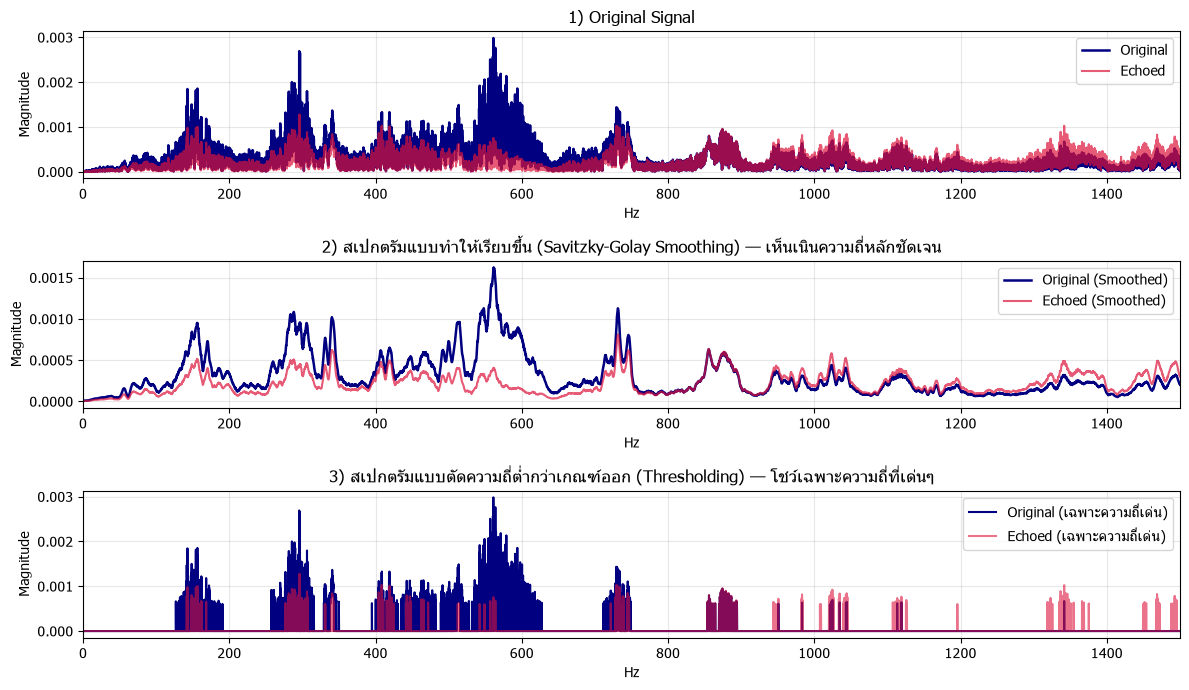

In [184]:
t, raw, echo, fs = get_scenario_audio(scenario=1, clip_idx1=0, reverb_level=1, lag_ms=0.0)
N = len(raw)
# 1. คำนวณ FFT ดิบ
freqs = np.fft.rfftfreq(N, d=1/fs)
mag_raw = np.abs(np.fft.rfft(raw)) / N
mag_echo = np.abs(np.fft.rfft(echo)) / N
# 2. แบบที่ A: ทำให้เส้นสเปกตรัมเรียบขึ้น (Smoothing ด้วย Savitzky-Golay จาก Lab 3/11)
mag_raw_smooth = savgol_filter(mag_raw, window_length=81, polyorder=3)
mag_echo_smooth = savgol_filter(mag_echo, window_length=81, polyorder=3)
# 3. แบบที่ B: ลบความถี่เบาๆ ออก โชว์เฉพาะความถี่เด่นๆ (Thresholding)
threshold = 0.20 * np.max(mag_raw)  # ตัดความถี่ที่ต่ำกว่า 20% ของยอดสูงสุดทิ้งเป็น 0
mag_raw_dom = np.where(mag_raw >= threshold, mag_raw, 0)
mag_echo_dom = np.where(mag_echo >= threshold, mag_echo, 0)
# พล็อตเปรียบเทียบ
plt.figure(figsize=(12, 7))
plt.subplot(3, 1, 1)
plt.plot(freqs, mag_raw, label="Original", color="navy", linewidth=1.8)
plt.plot(freqs, mag_echo, label="Echoed", color="crimson", alpha=0.7, linewidth=1.5)
plt.title("1) Original Signal")
plt.xlabel("Hz")
plt.ylabel("Magnitude")
plt.xlim(0, 1500)
plt.grid(True, alpha=0.3)
plt.legend()
# กราฟบน: แบบทำให้เรียบขึ้น (Smooth Envelope)
plt.subplot(3, 1, 2)
plt.plot(freqs, mag_raw_smooth, label="Original (Smoothed)", color="navy", linewidth=1.8)
plt.plot(freqs, mag_echo_smooth, label="Echoed (Smoothed)", color="crimson", alpha=0.7, linewidth=1.5)
plt.title("2) สเปกตรัมแบบทำให้เรียบขึ้น (Savitzky-Golay Smoothing) — เห็นเนินความถี่หลักชัดเจน")
plt.xlabel("Hz")
plt.ylabel("Magnitude")
plt.xlim(0, 1500)
plt.grid(True, alpha=0.3)
plt.legend()
# กราฟล่าง: แบบตัดความถี่น้อยๆ ออก โชว์เฉพาะยอดที่เด่นๆ
plt.subplot(3, 1, 3)
plt.plot(freqs, mag_raw_dom, label="Original (เฉพาะความถี่เด่น)", color="navy")
plt.plot(freqs, mag_echo_dom, label="Echoed (เฉพาะความถี่เด่น)", color="crimson", alpha=0.6)
plt.title("3) สเปกตรัมแบบตัดความถี่ต่ำกว่าเกณฑ์ออก (Thresholding) — โชว์เฉพาะความถี่ที่เด่นๆ")
plt.xlabel("Hz")
plt.ylabel("Magnitude")
plt.xlim(0, 1500)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


[Echo Lag] โหมด: สุ่มอัตโนมัติ (Random 3-20 ms) -> ใช้ Lag = 4.74 ms (76 samples)


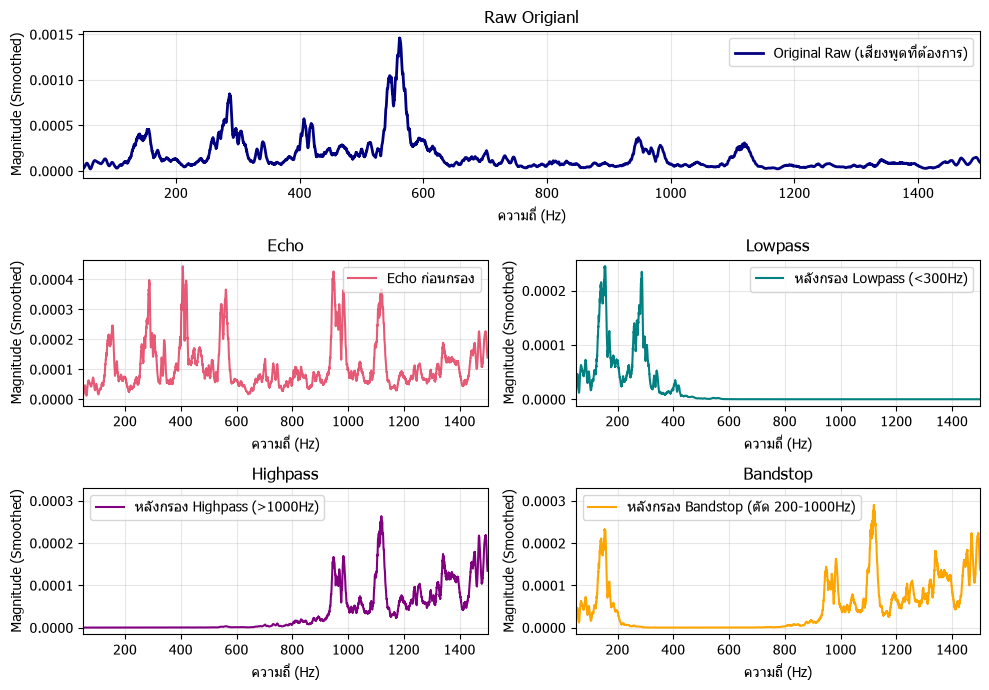

In [185]:
t, raw, echo, fs = get_scenario_audio(scenario=1, clip_idx1=0, reverb_level=1)
N = len(raw)

b_lp, a_lp = signal.butter(4, 300, btype="lowpass", fs=fs)
echo_lp = signal.filtfilt(b_lp, a_lp, echo)
b_hp, a_hp = signal.butter(4, 1000, btype="highpass", fs=fs)
echo_hp = signal.filtfilt(b_hp, a_hp, echo)
b_bs, a_bs = signal.butter(4, [200, 1000], btype="bandstop", fs=fs)
echo_bs = signal.filtfilt(b_bs, a_bs, echo)

def get_smooth_spectrum(sig, fs):
    w = hann(len(sig))
    mag = np.abs(np.fft.rfft(sig * w)) / len(sig)
    return savgol_filter(mag, window_length=81, polyorder=3)

freqs = np.fft.rfftfreq(N, d=1/fs)
plt.figure(figsize=(10, 7))
plt.subplot(3,1,1)
plt.plot(freqs, get_smooth_spectrum(raw, fs), label="Original Raw (เสียงพูดที่ต้องการ)", color="navy", linewidth=2)
plt.title("Raw Origianl")
plt.xlabel("ความถี่ (Hz)")
plt.ylabel("Magnitude (Smoothed)")
plt.xlim(50, 1500)
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(3,2,3)
plt.plot(freqs, get_smooth_spectrum(echo, fs), label="Echo ก่อนกรอง", color="crimson", alpha=0.7)
plt.title("Echo")
plt.xlabel("ความถี่ (Hz)")
plt.ylabel("Magnitude (Smoothed)")
plt.xlim(50, 1500)
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(3,2,4)
plt.plot(freqs, get_smooth_spectrum(echo_lp, fs), label="หลังกรอง Lowpass (<300Hz)", color="teal")
plt.title("Lowpass")
plt.xlabel("ความถี่ (Hz)")
plt.ylabel("Magnitude (Smoothed)")
plt.xlim(50, 1500)
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(3,2,5)
plt.plot(freqs, get_smooth_spectrum(echo_hp, fs), label="หลังกรอง Highpass (>1000Hz)", color="purple")
plt.title("Highpass")
plt.xlabel("ความถี่ (Hz)")
plt.ylabel("Magnitude (Smoothed)")
plt.xlim(50, 1500)
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(3,2,6)
plt.plot(freqs, get_smooth_spectrum(echo_bs, fs), label="หลังกรอง Bandstop (ตัด 200-1000Hz)", color="orange")
plt.title("Bandstop")
plt.xlabel("ความถี่ (Hz)")
plt.ylabel("Magnitude (Smoothed)")
plt.xlim(50, 1500)
plt.legend()
plt.grid(True, alpha=0.3)




plt.tight_layout()
plt.show()

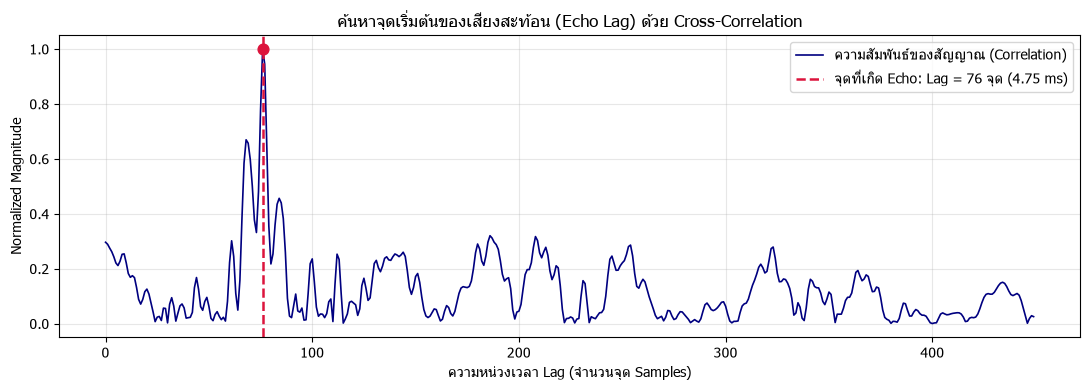

In [186]:
seg_len = fs * 1
corr = np.correlate(echo[:seg_len], raw[:seg_len], mode="full")
lags = np.arange(-seg_len + 1, seg_len)
max_lag_show = 450
zero_idx = seg_len - 1
# ตัดมาเฉพาะช่วง Lag 0 ถึง 450 จุด และทำเป็นค่าความแรง (0 ถึง 1)
lags_view = lags[zero_idx : zero_idx + max_lag_show]
corr_view = np.abs(corr[zero_idx : zero_idx + max_lag_show])
corr_view = corr_view / np.max(corr_view)
# ค้นหาจุดที่เกิด Echo แรงที่สุดอัตโนมัติด้วย np.argmax
detected_lag = lags_view[np.argmax(corr_view)]
detected_ms = detected_lag / fs * 1000
plt.figure(figsize=(11, 4))
# 1. พล็อตกราฟเส้น (ไม่ใช้ stem เพื่อไม่ให้เส้นถี่ทับกัน)
plt.plot(lags_view, corr_view, color="navy", linewidth=1.2, label="ความสัมพันธ์ของสัญญาณ (Correlation)")
# 2. ปักหมุดสีแดงและตีเส้นประตรงจุดที่ตรวจพบ Echo
plt.axvline(detected_lag, color="crimson", linestyle="--", linewidth=1.8,
            label=f"จุดที่เกิด Echo: Lag = {detected_lag} จุด ({detected_ms:.2f} ms)")
plt.scatter([detected_lag], [1.0], color="crimson", s=60, zorder=5)
plt.title("ค้นหาจุดเริ่มต้นของเสียงสะท้อน (Echo Lag) ด้วย Cross-Correlation")
plt.xlabel("ความหน่วงเวลา Lag (จำนวนจุด Samples)")
plt.ylabel("Normalized Magnitude")
plt.legend(loc="upper right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
lj;p
# # 4. พล็อตพิสูจน์ผลลัพธ์
# plt.figure(figsize=(14, 8))
# # กราฟบน: เทียบสเปกตรัมความถี่ FFT (Raw vs Echo)
# plt.subplot(2, 1, 1)
# plt.plot(freqs, mag_echo, label="สเปกตรัมเสียงที่ผ่านห้องสะท้อน (Echo)", color="crimson", alpha=0.7)
# plt.plot(freqs, mag_raw, label="สเปกตรัมเสียงพูดต้นฉบับ (Raw)", color="navy", alpha=0.7)
# plt.xlim(0, 1500)
# plt.title("1) พิสูจน์ด้วย FFT: ความถี่ของเสียงสะท้อน (Echo) ทับซ้อนกับเสียงพูดต้นฉบับ (Raw) 100%", fontsize=11, fontweight="bold")
# plt.xlabel("ความถี่ (Hz)")
# plt.ylabel("Magnitude")
# plt.legend()
# plt.grid(True, alpha=0.3)
# # กราฟล่าง: ซูมดูผลลัพธ์เมื่อฝืนใช้ Lowpass / Bandstop กรอง (ช่วง 1.00 - 1.04 วินาที)
# plt.subplot(2, 1, 2)
# s_idx, e_idx = int(1.00 * fs), int(1.04 * fs)
# plt.plot(t[s_idx:e_idx], raw[s_idx:e_idx], label="ต้นฉบับจริงที่ต้องการ (Raw)", color="navy", linewidth=2)
# plt.plot(t[s_idx:e_idx], echo[s_idx:e_idx], label="ก่อนกรอง (Echo)", color="crimson", linestyle="--", alpha=0.6)
# plt.plot(t[s_idx:e_idx], echo_lowpass[s_idx:e_idx], label="หลังใช้ Lowpass 500Hz (เสียงบี้/เพี้ยน)", color="teal")
# plt.plot(t[s_idx:e_idx], echo_bandstop[s_idx:e_idx], label="หลังใช้ Bandstop 300-2500Hz (เนื้อเสียงหาย)", color="orange")
# plt.title("2) พิสูจน์ในโดเมนเวลา: การใช้ Lowpass / Bandstop ทำให้รูปคลื่นเสียงพูดเสียหายโดยไม่ได้แก้ปัญหา Echo", fontsize=11, fontweight="bold")
# plt.xlabel("เวลา (วินาที)")
# plt.ylabel("Amplitude")
# plt.legend(loc="upper right")
# plt.grid(True, alpha=0.3)
# plt.tight_layout()
# plt.show()